In [6]:
import torch
import torch.nn as nn
import numpy as np
import random
import numpy as np
from torch.amp import autocast, GradScaler
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint
import matplotlib.pyplot as plt
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.version.cuda)
print(f"running on {device}")

LOAD_SPECTROGRAM_FLAG = True

13.4
running on cuda


In [2]:
class EncoderLayer(nn.Module):
    def __init__(self, c_in, c_out, p_dropout=0.05, scale = 2):
        super().__init__()
        self.c_stack = nn.Sequential(
            nn.Conv2d(c_in, c_out, kernel_size=5, padding=2),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, kernel_size=5, padding=2),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
        )

        self.dropout = nn.Dropout(p = p_dropout)
        self.pool = nn.MaxPool2d(scale, scale)

    def forward(self, x):
        h = checkpoint(self.c_stack, x, use_reentrant=False)
        h = self.dropout(h)
        return self.pool(h), h


class DecoderLayer(nn.Module):
    def __init__(self, c_in, c_skip, c_out, p_dropout=0.1, scale = 2):
        super().__init__()

        self.c_stack = nn.Sequential(
            nn.Conv2d(c_in + c_skip, c_in, kernel_size=5, padding=2),
            nn.BatchNorm2d(c_in),
            nn.ReLU(inplace=True),
            nn.Conv2d(c_in, c_out, kernel_size=5, padding=2),
            nn.BatchNorm2d(c_out),
            nn.ReLU(inplace=True),
        )
        self.upsample = nn.ConvTranspose2d(c_in, c_in, kernel_size=2, stride=2)

        self.dropout = nn.Dropout(p = p_dropout)

    def forward(self, x_skip, x_low):
        upsampled = self.upsample(x_low)
        x_combined = torch.cat([x_skip, upsampled], dim=1)
        
        h = checkpoint(self.c_stack, x_combined, use_reentrant=False)
        return self.dropout(h)

class UNet(nn.Module):
    def __init__(self, output_classes, layer_count, raw_channels, channel_outs, scale=2):
        super().__init__()
        self.layer_count = layer_count
        self.scale = scale

        if channel_outs is None:
            channel_outs = [64, 96, 128, 128, 96, 64]

        self.first = nn.Sequential( 
            nn.Conv2d(in_channels=raw_channels, out_channels=channel_outs[0], kernel_size=7, padding=3, stride=1, bias=False),
            nn.BatchNorm2d(channel_outs[0]),
            nn.ReLU(inplace=True),
            nn.Conv2d(channel_outs[0], channel_outs[0], kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channel_outs[0]),
            nn.ReLU(inplace=True)
        )

        self.down = nn.MaxPool2d(self.scale, self.scale)

        self.encoders = nn.ModuleList([
            EncoderLayer(channel_outs[i], channel_outs[i+1], scale=self.scale) for i in range(layer_count-1)# 1->2, 2->3
        ])

        self.bottom_layer = nn.Sequential( 
            nn.Conv2d(channel_outs[layer_count-1], channel_outs[layer_count-1], kernel_size=3, padding=1, stride=1, bias=False),
            nn.BatchNorm2d(channel_outs[layer_count-1]),
            nn.ReLU(inplace=True),
            nn.Conv2d(channel_outs[layer_count-1], channel_outs[layer_count], kernel_size=3, padding=1, stride=1, bias=False),
            nn.BatchNorm2d(channel_outs[layer_count]),
            nn.ReLU(inplace=True)
        )

        self.decoders = nn.ModuleList([
            DecoderLayer(channel_outs[i], channel_outs[-i - 1], channel_outs[i+1], scale=self.scale) # 3->2 (no resid), 2->1 (resid from encoders[0])
            for i in range(layer_count, len(channel_outs)-1)
        ])

        self.upscaler = nn.Sequential(
            nn.Conv2d(channel_outs[-1], channel_outs[-1]*(self.scale**2), kernel_size=1, stride=1, padding=0),
            nn.PixelShuffle(self.scale)
        )

        self.out = nn.Sequential( 
            nn.Conv2d(channel_outs[-1] + channel_outs[0], channel_outs[-1], kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channel_outs[-1]),
            nn.ReLU(inplace=True),
            nn.Conv2d(channel_outs[-1], output_classes, kernel_size=3, padding=1, stride=1) # No activation on logits head
        )

    def forward(self, x):

        first_act = self.first(x)
        activations = [first_act]
        h = self.down(first_act)
        for encoder in self.encoders:
            h, a_map = encoder(h)
            activations.append(a_map)

        up = self.bottom_layer(h)

        for i, decoder in enumerate(self.decoders):
            up = decoder(activations[-i - 1], up)

        up = self.upscaler(up)

        return self.out(torch.cat([activations[0], up], dim = 1))

In [3]:
scaler = GradScaler('cuda')

channel_outs = [32, 64, 128, 256, 384, 512]
layer_ct = len(channel_outs)

model = UNet(raw_channels=1, output_classes=2, layer_count=layer_ct, channel_outs=channel_outs + channel_outs[::-1]).to(device)
criterion = torch.nn.L1Loss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

# print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 60,820,546


In [4]:
class LazyDiskDataset(Dataset):
    def __init__(self, file_dict : dict):
        self.file_dict = file_dict
        self.keys = sorted(self.file_dict.keys())

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, index):
        path_dictionary = self.file_dict[self.keys[index]]
        return {
            name: np.load(path) for name, path in path_dictionary.items()
        }

def truncate_collate(batch_list):
    min_length = min(
        item[key].shape[1] 
        for item in batch_list 
        for key in ["mixture", "noise", "clean"]
    )
    min_height = min(
        item[key].shape[0]
        for item in batch_list
        for key in ["mixture", "noise", "clean"]
    )
    
    min_length = (min_length // (2**len(channel_outs))) * 2**(len(channel_outs))
    min_height = (min_height // (2**len(channel_outs))) * 2**(len(channel_outs))

    CROP_L = 1024 
    target_l = min(CROP_L, min_length)
    max_x = min_length - target_l
    start_x = random.randint(0, max_x) if max_x > 0 else 0
    
    collated_batch = {}
    keys = batch_list[0].keys()
    
    for key in keys:
        truncated_tensors = []
        for item in batch_list:

            arr = item[key] 
            truncated_arr = arr[:min_height, start_x:start_x + target_l]
            tensor = torch.from_numpy(truncated_arr)[None, ...]
            truncated_tensors.append(tensor)

        collated_batch[key] = torch.stack(truncated_tensors, dim=0)
        
    return collated_batch



dataset_path = "/ws/data/spectrogram/numpy-files"
files = {}
target_files = ["clean.npy", "mixture.npy", "noise.npy"]

for item in os.listdir(dataset_path):
    child_folder_path = os.path.join(dataset_path, item)
    
    if os.path.isdir(child_folder_path):
        print(f"Checking folder: {item}")
        
        # Check for each of the 3 files
        found = {}
        for filename in target_files:
            file_path = os.path.join(child_folder_path, filename)
            if os.path.exists(file_path):
                print(f"  -> Found: {filename}")
                found[filename.split(".")[0]] = file_path
            else:
                print(f"  -> MISSING: {filename}")

        if (len(found.keys()) == len(target_files)):
            print(f"all files found, adding to key {item}")
            files[item] = found

dataset = LazyDiskDataset(files)
train_loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    prefetch_factor=1,
    collate_fn=truncate_collate
) 

Checking folder: 008372
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 008372
Checking folder: 053589
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 053589
Checking folder: 052644
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 052644
Checking folder: 054621
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 054621
Checking folder: 059657
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 059657
Checking folder: 106955
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 106955
Checking folder: 114390
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.npy
all files found, adding to key 114390
Checking folder: 064408
  -> Found: clean.npy
  -> Found: mixture.npy
  -> Found: noise.np

In [5]:
EMA_RATIO = 0.8

running_loss_clean = 0.0
running_loss_noise = 0.0
for epoch in range(50):
    model.train()
    batches = 0

    progress = tqdm(train_loader)

    for batch in progress:
        cleans = batch["clean"].to(device, non_blocking=True)
        noises = batch["noise"].to(device, non_blocking=True)
        mixture = batch["mixture"].to(device, non_blocking=True)

        mixture.requires_grad_()
        optimizer.zero_grad()

        with autocast('cuda'):
            logits = model(mixture)
            
        clean_loss = criterion(logits[:, 0], cleans.squeeze(1))
        noise_loss = criterion(logits[:, 1], noises.squeeze(1))

        scaler.scale(clean_loss + noise_loss).backward()
        scaler.unscale_(optimizer)
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        scaler.step(optimizer)
        scaler.update()

        running_loss_clean = EMA_RATIO*running_loss_clean + (1-EMA_RATIO)*clean_loss.item()
        running_loss_noise = EMA_RATIO*running_loss_noise + (1-EMA_RATIO)*noise_loss.item()
        batches += 1

        progress.set_postfix({
            "c_loss": f"{running_loss_clean:.4f}",
            "n_loss": f"{running_loss_noise:.4f}"
        })
    torch.save(model.state_dict(), f'checkpoints/full/spectrogram_{running_loss_clean + running_loss_noise:.4f}.pt')

100%|██████████| 342/342 [07:32<00:00,  1.32s/it, c_loss=4.5748, n_loss=3.6531]


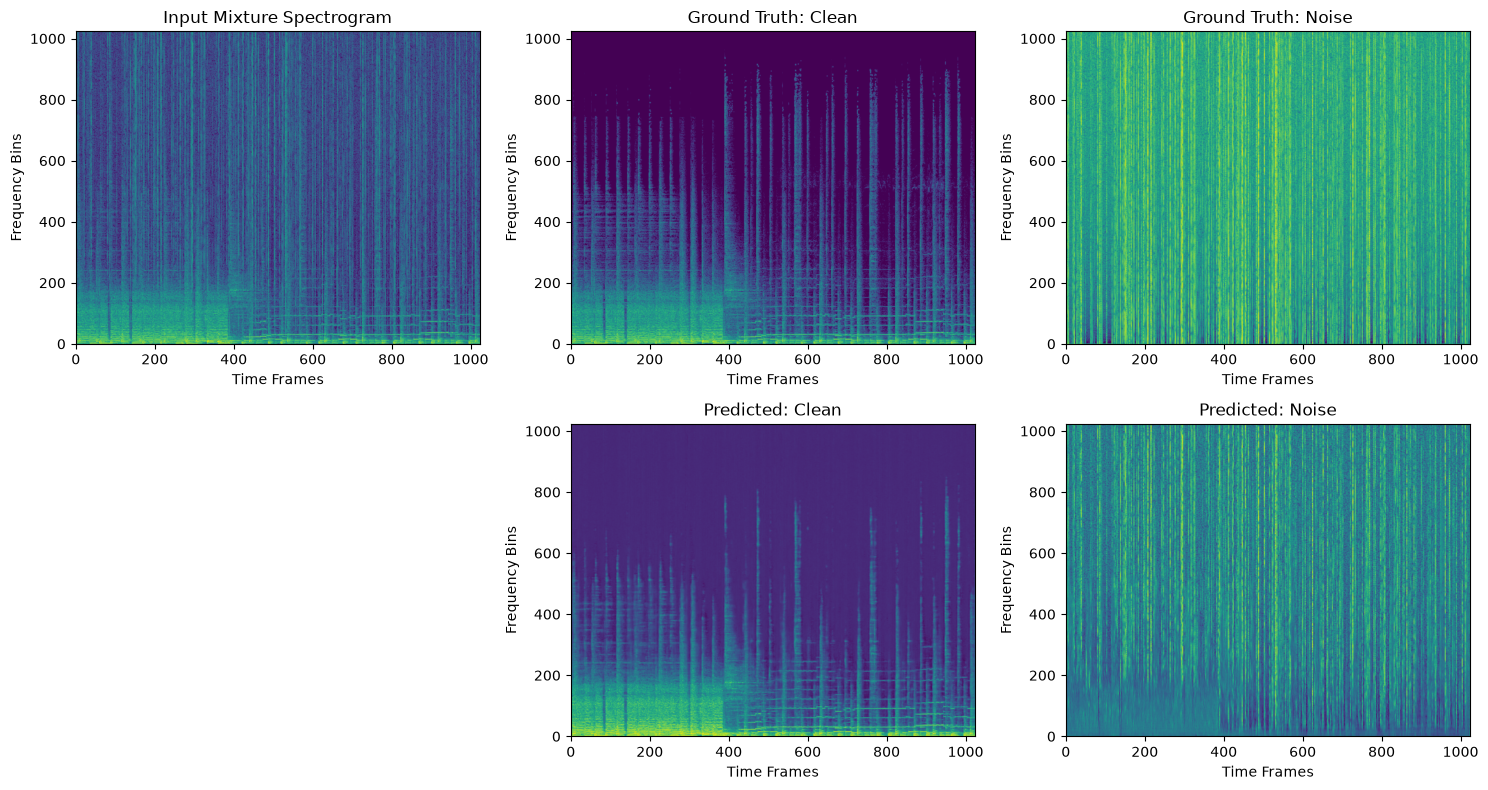

In [7]:

# Initialize model architecture and load weights safely
# model.load_state_dict(torch.load("checkpoints/full/spectrogram_7.4644", map_location=device, weights_only=True))
model.eval()

# 2. Extract a sample batch from your DataLoader
# We use the train_loader since it's already structured in your notebook
batch = next(iter(train_loader))

mixture_tensor = batch["mixture"][0:1].to(device)  # shape: [1, 1, H, W]
clean_gt = batch["clean"][0].squeeze().numpy()     # Ground truth clean
noise_gt = batch["noise"][0].squeeze().numpy()     # Ground truth noise
mix_img = batch["mixture"][0].squeeze().numpy()    # Ground truth mixture

# 3. Perform inference without computing gradients
with torch.no_grad():
    logits = model(mixture_tensor)
    # Your model has no final activation function, so we clip or directly view outputs
    predictions = logits.squeeze(0).cpu().numpy()  # shape: [2, H, W]

pred_clean = predictions[0]
pred_noise = predictions[1]

# 4. Plot 2x3 grid to directly compare ground truth vs predictions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Column 1: Mixture Input
axes[0, 0].imshow(mix_img, aspect='auto', origin='lower', cmap='viridis')
axes[0, 0].set_title("Input Mixture Spectrogram")
axes[1, 0].axis('off') # Keep grid clean since input applies to both outputs

# Column 2: Clean Source (GT vs Prediction)
axes[0, 1].imshow(clean_gt, aspect='auto', origin='lower', cmap='viridis')
axes[0, 1].set_title("Ground Truth: Clean")
axes[1, 1].imshow(pred_clean, aspect='auto', origin='lower', cmap='viridis')
axes[1, 1].set_title("Predicted: Clean")

# Column 3: Noise Source (GT vs Prediction)
axes[0, 2].imshow(noise_gt, aspect='auto', origin='lower', cmap='viridis')
axes[0, 2].set_title("Ground Truth: Noise")
axes[1, 2].imshow(pred_noise, aspect='auto', origin='lower', cmap='viridis')
axes[1, 2].set_title("Predicted: Noise")

# Clean up axes styling
for ax in axes.flatten():
    if ax.axison:
        ax.set_xlabel("Time Frames")
        ax.set_ylabel("Frequency Bins")

plt.tight_layout()
plt.show()

In [ ]:
import librosa
import numpy as np
import soundfile as sf
from pathlib import Path

# --- Configuration ---
# 1. Provide the expected sample rate (e.g., 22050, 44100, etc.)
# This dictates the playback speed of your reconstructed audio file.
TARGET_SR = 44100  

for pair in (("mix", mix_img), ("pred", pred_clean), ("clean", clean_gt)):
    name, tens = pair[0], pair[1]
    # 2. Set up your output path
    output_dir = Path("../data/spectrogram/reconstructed-audio")
    output_dir.mkdir(parents=True, exist_ok=True)
    save_path = output_dir / f"reconstructed_{name}.wav"


    # --- Reconstruct Array to Audio ---
    try:
        print(f"Converting '{name}' to audio...")

        # 1. Reverse the decibel conversion back to linear amplitude
        # (Matches your script's librosa.amplitude_to_db transformation)
        magnitude = librosa.db_to_amplitude(tens, ref=1.0)

        # 2. Reconstruct the phase using Griffin-Lim
        # Uses Librosa's default STFT parameters (n_fft=2048, hop_length=512)
        y_reconstructed = librosa.griffinlim(
            magnitude,
            n_iter=32,       # 32 iterations provides a solid quality-to-speed balance
            hop_length=512,
            win_length=None  # Matches default n_fft
        )

        # 3. Peak-normalize the waveform to prevent digital clipping
        y_normalized = librosa.util.normalize(y_reconstructed)

        # 4. Write directly to a WAV file
        sf.write(save_path, y_normalized, TARGET_SR)
        print(f"🎉 Success! Audio saved directly to: {save_path}")

    except Exception as e:
        print(f"Error during audio reconstruction: {e}")

Converting 'pred_clean' to audio...
🎉 Success! Audio saved directly to: ../data/spectrogram/reconstructed-audio/reconstructed_mix.wav
